# DSA 4060XA – Week 6 Guided Practical Lab: Evaluating Recommender Systems

| Field | Detail |
|---|---|
| **Name** | Hans Onesmo |
| **Student ID** | 671463 |
| **Course** | DSA 4060XA – Recommender Systems |
| **Models compared** | Popularity Baseline • Content-Based Filtering • Item-Based Collaborative Filtering |

## Step 1 – Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


**Student Check – Answers**

1. One row in `movies` represents **one movie** in the catalogue: its `movie_id`, `title` and pipe-separated `genres`.
2. One row in `ratings` represents **one user's rating of one movie** at a point in time (`user_id`, `movie_id`, `rating`, `timestamp`).
3. There are **12 unique users** and **20 unique movies** (120 ratings in total, 10 per user).
4. The `rating` column is **explicit feedback**: users directly state how much they liked a movie.
5. The rating scale is **1–5** (the values that actually occur are 2, 3, 4 and 5).

## Step 3 – Inspect Rating Behaviour

rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

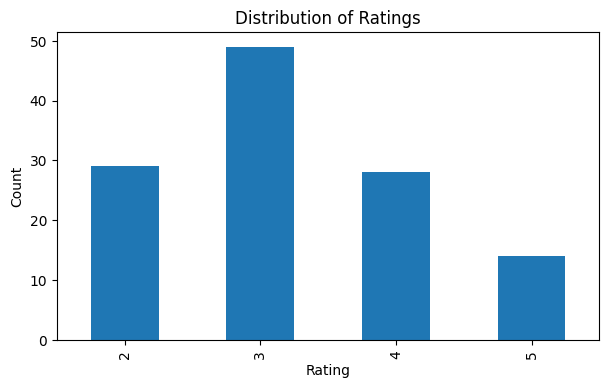

In [3]:
display(ratings["rating"].value_counts().sort_index())

plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Interpretation:** Middle ratings dominate rather than very high or very low ones. A rating of 3 is the most common (49 of 120 ratings, about 41%), followed by 2 (29) and 4 (28), while 5 is the rarest (14) and no one gave a 1. Only 42 of the 120 ratings (35%) are 4 or 5, so "relevant" items (rating ≥ 4) are scarce. This matters for evaluation: the ranking metrics later will be based on very few relevant test items, and because ratings cluster tightly around 2–4, a model that simply predicts the average can already look reasonable on MAE and RMSE.

## Step 4 – Create a Train/Test Split

For every user the **most recent** interaction (highest timestamp) is held out as test data; everything earlier is training data.

In [4]:
ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


## Step 5 – Build a Popularity Baseline

In [5]:
global_mean = train["rating"].mean()
print("Global training mean:", round(global_mean, 3))

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

display(movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10))

Global training mean: 3.222


,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


In [6]:
movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)
display(baseline_test.head())

,user_id,movie_id,rating,timestamp,prediction
9,1,14,4,10,2.857143
19,2,9,4,20,3.000000
29,3,18,3,30,4.000000
39,4,18,3,40,4.000000
49,5,11,2,50,2.500000


## Step 6 – Evaluate the Baseline with MAE and RMSE

In [7]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE:

 1.086
Baseline RMSE: 1.201


## Step 7 – Build Item Features for Content-Based Filtering

In [8]:
genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


## Step 8 – Build a User Preference Profile

In [9]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)
profile_series = pd.Series(profile, index=genre_columns).sort_values(ascending=False)
display(profile_series.to_frame("profile_weight"))

,profile_weight
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


In [10]:
# Evidence for the Student Task: User 1's training history, highest rated first
user1_hist = (
    train[train["user_id"] == 1]
    .merge(movies, on="movie_id")
    [["title", "genres", "rating"]]
    .sort_values("rating", ascending=False)
    .reset_index(drop=True)
)
display(user1_hist)

,title,genres,rating
0,Galaxy Mission,Action|Sci-Fi,5
1,Digital Dreams,Sci-Fi|Drama,4
2,Love in Nairobi,Romance|Drama,3
3,Wedding Weekend,Romance|Comedy,3
4,Hidden Truth,Drama|Mystery,3
5,City Detectives,Crime|Drama,3
6,Family Weekend,Comedy|Family,3
7,Home Again,Family|Drama,2
8,Weekend Escape,Comedy|Adventure,2


**Student task – User 1's two strongest genre preferences:** Drama (weight 1.67) and Sci-Fi (weight 1.00).

**Do they agree with the highly rated movies?** Only partly. User 1's two highest-rated movies are Galaxy Mission (5, Action|Sci-Fi) and Digital Dreams (4, Sci-Fi|Drama), so **Sci-Fi** is clearly backed by their best ratings. **Drama**, however, ranks first mainly because it appears in 5 of the 9 training movies (Digital Dreams, Love in Nairobi, Hidden Truth, City Detectives, Home Again), most of which the user rated only 3 or 2. This shows a weakness of this profile: it rewards how often a genre appears as well as how much the user liked it, so frequently watched but only mildly liked genres can outrank a genre the user loved.

## Step 9 – Content-Based Rating Prediction

In [11]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Build Item-Based Collaborative Filtering

In [12]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

display(item_similarity.iloc[:5, :5])

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


## Step 11 – Item-Based Rating Prediction

In [13]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0

    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


## Step 12 – Compare Rating Prediction Metrics

In [14]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


**Student Check – Answers**

6. **Lowest MAE:** Item-Based CF (0.924), then the Popularity Baseline (1.086), then Content-Based (1.094).
7. **Lowest RMSE:** Item-Based CF (1.070), then the Popularity Baseline (1.201), then Content-Based (1.381).
8. **Does either advanced model clearly beat the baseline?** Item-Based CF improves on the baseline by about 0.16 MAE points (about 15%) and 0.13 RMSE points (about 11%), so it is better, although the test set has only 12 ratings, so the gap is not conclusive. Content-Based does **not** beat the baseline: its MAE is slightly worse and its RMSE is clearly worse (1.381 vs 1.201), which means it makes some large errors.
9. **Why not pick the best model from one metric?** MAE and RMSE treat errors differently (RMSE punishes large errors), and both only measure how close predicted ratings are. They say nothing about whether the model puts relevant movies at the top of a list. As the next steps show, Item-Based CF is best at rating prediction but worst at ranking, so a single metric would give a misleading answer.

## Step 13 – Move from Rating Prediction to Ranking Evaluation

**Relevance rule:** a held-out item is relevant if its actual rating is 4 or 5.

In [15]:
test["relevant"] = test["rating"] >= 4
display(test[["user_id", "movie_id", "rating", "relevant"]].head(12))
print("Users whose held-out item is relevant:", int(test["relevant"].sum()), "of", len(test))

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False
59,6,2,5,True
69,7,3,2,False
79,8,12,2,False
89,9,16,2,False
99,10,19,3,False


Users whose held-out item is relevant: 5 of 12


## Step 14 – Build Top-N Recommendation Functions

In [16]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]


Content: [16, 6, 18]


Collaborative: [12, 11, 18]


In [17]:
# Same lists, shown with titles and genres for the discussion
title_map = movies.set_index("movie_id")["title"].to_dict()
genre_map = movies.set_index("movie_id")["genres"].to_dict()
for name, fn in [("Popularity", recommend_popularity), ("Content-Based", recommend_content), ("Item-Based CF", recommend_cf)]:
    print(name)
    for m in fn(1):
        print(f"   {m:>2}  {title_map[m]:<22} {genre_map[m]}")

Popularity
    6  Broken Hearts          Drama|Romance
   18  The Promise            Romance|Drama
   16  Campus Life            Comedy|Drama
Content-Based


   16  Campus Life            Comedy|Drama
    6  Broken Hearts          Drama|Romance
   18  The Promise            Romance|Drama
Item-Based CF
   12  The Last Case          Mystery|Crime
   11  Laugh Out Loud         Comedy
   18  The Promise            Romance|Drama


**Discussion:** For User 1 the Popularity list (Broken Hearts, The Promise, Campus Life) and the Content-Based list (Campus Life, Broken Hearts, The Promise) contain **exactly the same three movies in a different order**, so the content model adds almost no personalization for this user. The Item-Based CF list (The Last Case, Laugh Out Loud, The Promise) is the most different, and therefore the **most personalized**, since it is driven by what similar movies other users rated rather than by overall average rating. The **Popularity** list is the **easiest to explain** ("these are the highest-rated movies you have not seen"); the content list is also explainable through genres, while the CF list is the hardest to justify to a user.

## Step 15 – Precision@K, Recall@K and NDCG@K

In [18]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        if not relevant:
            continue

        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


**Interpretation:** Only 5 of the 12 users have a relevant held-out movie (rating ≥ 4), and each has just one, so the best possible Precision@3 is 1/3 and every hit moves the averages a lot. **Content-Based** and the **Popularity Baseline** tie on Precision@3 (0.067) and Recall@3 (0.20), each finding the relevant movie for 1 of the 5 users. Content-Based has the better **NDCG@3 (0.20 vs 0.10)** because its hit appeared at rank 1, while the popularity hit was lower in the list. **Item-Based CF scored 0 on all three ranking metrics**, even though it had the best MAE and RMSE. So good rating prediction did not translate into a good Top-3 list here.

## Step 16 – Catalogue Coverage

In [19]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

In [20]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


## Step 18 – Diversity

In [21]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


## Step 19 – Build a Unified Evaluation Table

In [22]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

summary.round(3)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


## Step 20 – Interpret Evaluation Trade-Offs

**Findings for coverage, novelty and diversity (from the summary table above):**
- **Coverage:** Popularity Baseline 0.35 (only 7 of the 20 movies are ever recommended), Content-Based 0.70, Item-Based CF 0.85. The baseline pushes the same few titles to everyone.
- **Novelty:** Item-Based CF (1.695) and Popularity (1.689) are about equal, and Content-Based is lowest (1.344), meaning its recommendations lean toward more commonly rated movies.
- **Diversity:** Item-Based CF is the most diverse (0.780), then Popularity (0.736), and Content-Based is the least diverse (0.542), because it recommends movies with overlapping genres.

**Trade-offs seen in this lab:**
- **Accuracy vs ranking:** Item-Based CF has the best MAE/RMSE but zero Precision, Recall and NDCG at K = 3, so being accurate on ratings did not mean a useful Top-3 list.
- **Relevance vs breadth:** The Popularity Baseline matches the content model on Precision/Recall but covers only 35% of the catalogue, so it would show the same few movies to everyone.
- **Relevance vs variety:** The Content-Based model has the best NDCG and 70% coverage, but its lists are the least diverse and least novel (genre-narrow, "more of the same").
- **Explainability vs accuracy:** The popularity list is the easiest to explain but is not personalized, while the CF list is the most personalized but the hardest to explain.

There is no single best model on every measure; the right choice depends on the business objective.

## Step 21 – Final Business Scenario

> "We want users to discover relevant movies, but we do not want the same popular titles to dominate every recommendation list."

**10. Which model would you choose?** The **Content-Based recommender**.

**11. Which 2–3 metrics influenced the choice most?**
- **NDCG@3 (0.20)** and **Recall@3 (0.20):** it is the only model that matched or beat the baseline on relevance, and it ranked its hit highest (NDCG is twice the baseline's 0.10).
- **Catalogue coverage (0.70 vs 0.35):** it exposes twice as much of the catalogue as the popularity baseline, which directly addresses the worry about the same popular titles dominating.
- Item-Based CF has the best coverage (0.85) and diversity, but it found no relevant movies in the Top-3 (Precision/Recall/NDCG = 0), which fails the "discover *relevant* movies" half of the goal.

**12. What trade-off am I accepting?** Lower novelty (1.34, the lowest) and lower diversity (0.54, the lowest). Content-based lists are genre-narrow, so users may get "more of the same" and may not discover movies outside their usual genres.

**13. One limitation of this evaluation:** The test set is tiny, with one held-out rating for each of 12 users and only 5 relevant items, so a single extra hit changes the ranking metrics by 0.2 or more. The differences between the models are therefore not statistically reliable, and offline metrics cannot show how real users would respond.

## Step 22 – Extension Challenge (Option A – Change K)

I evaluate K = 1, 3 and 5 for all three models.

,K,Model,Precision@K,Recall@K,NDCG@K
0,1,Popularity Baseline,0.000,0.0,0.000
1,1,Content-Based,0.200,0.2,0.200
2,1,Item-Based CF,0.000,0.0,0.000
3,3,Popularity Baseline,0.067,0.2,0.100
4,3,Content-Based,0.067,0.2,0.200
5,3,Item-Based CF,0.000,0.0,0.000
6,5,Popularity Baseline,0.040,0.2,0.100
7,5,Content-Based,0.080,0.4,0.277
8,5,Item-Based CF,0.040,0.2,0.077


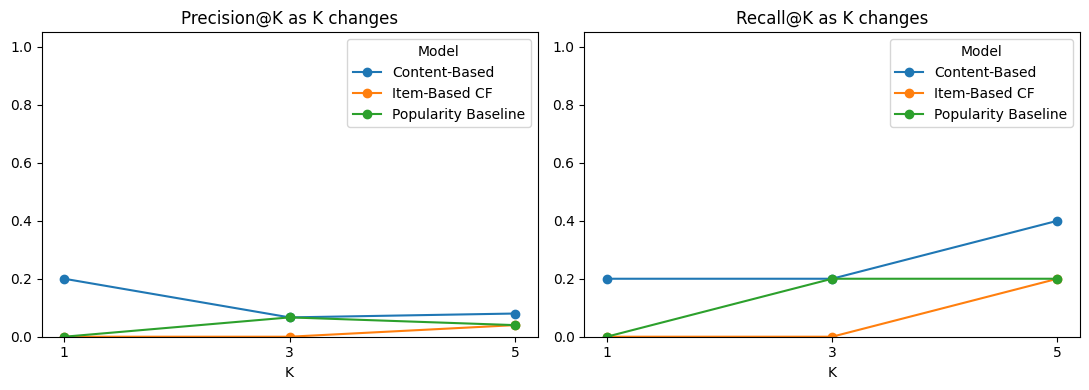

In [23]:
rows = []
for k in [1, 3, 5]:
    for name, fn in [("Popularity Baseline", recommend_popularity),
                     ("Content-Based", recommend_content),
                     ("Item-Based CF", recommend_cf)]:
        res = evaluate_ranking(fn, k)
        rows.append({
            "K": k,
            "Model": name,
            "Precision@K": res["Precision@3"],
            "Recall@K": res["Recall@3"],
            "NDCG@K": res["NDCG@3"]
        })

k_results = pd.DataFrame(rows)
display(k_results.round(3))

pivot = k_results.pivot(index="K", columns="Model", values=["Precision@K", "Recall@K"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["Precision@K", "Recall@K"]):
    pivot[metric].plot(marker="o", ax=ax)
    ax.set_title(metric + " as K changes")
    ax.set_xlabel("K")
    ax.set_xticks([1, 3, 5])
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Explanation – effect of changing K (Option A):**
- **Recall@K never goes down as K grows**, and it rises when a longer list catches a relevant movie the shorter list missed. Content-Based Recall goes 0.2 → 0.2 → 0.4 for K = 1, 3, 5. Popularity goes 0.0 → 0.2 → 0.2 and Item-Based CF goes 0.0 → 0.0 → 0.2, so a longer list gives each model more chances to find the user's relevant movie.
- **Precision@K tends to fall as K grows**, because the list gets longer while each user has only one relevant item. For example, Content-Based Precision drops from 0.200 at K = 1 to 0.067 at K = 3, and it only recovers slightly to 0.080 at K = 5 when a second user's relevant movie enters the list. Popularity Precision also falls from 0.067 at K = 3 to 0.040 at K = 5.
- The model ranking depends on K: at K = 1 only Content-Based finds anything, and at K = 5 it is still best (Precision 0.080, Recall 0.40, NDCG 0.277), while Item-Based CF only starts to score at K = 5. This supports choosing Content-Based, but with so few relevant items the pattern should be treated as indicative only.